In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os

In [2]:
train_df = pd.read_csv('Dataset/Train.csv')
test_df = pd.read_csv('Dataset/Test.csv')
sub_df = pd.read_csv('Dataset/Submission.csv')

In [3]:
train_df.head()

,Holiday,Temperature,Rainfall_last_hour,Snowfall_last_hour,Cloud_Cover,Weather,Weather_Desc,TimeStamp,Date,Traffic_Vol
0,NaN,289.28,0.0,0.0,40,Cloudy skies,Partly cloudy skies,02/10/08 9:00,02/10/08,5555
1,NaN,290.26,0.0,0.0,75,Cloudy skies,Fragmented clouds,02/10/08 10:00,02/10/08,4525
2,NaN,290.28,0.0,0.0,90,Cloudy skies,Full cloud cover,02/10/08 11:00,02/10/08,4772
3,NaN,290.33,0.0,0.0,90,Cloudy skies,Full cloud cover,02/10/08 12:00,02/10/08,5031
4,NaN,292.14,0.0,0.0,75,Cloudy skies,Fragmented clouds,02/10/08 13:00,02/10/08,4928


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

In [ ]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, concatenate, Dropout, BatchNormalization

import warnings
warnings.filterwarnings('ignore')

In [8]:
train_df['TimeStamp'] = pd.to_datetime(train_df['TimeStamp'], format='%d/%m/%y %H:%M')

In [9]:
train_df['Hour'] = train_df['TimeStamp'].dt.hour
train_df['Day'] = train_df['TimeStamp'].dt.day
train_df['Month'] = train_df['TimeStamp'].dt.month
train_df['Year'] = train_df['TimeStamp'].dt.year
train_df['Weekday'] = train_df['TimeStamp'].dt.weekday

In [10]:
train_df.set_index('TimeStamp', inplace=True)

In [11]:
train_df.index.min()

Timestamp('2008-10-02 09:00:00')

In [12]:
train_df.index.max()

Timestamp('2014-06-30 23:00:00')

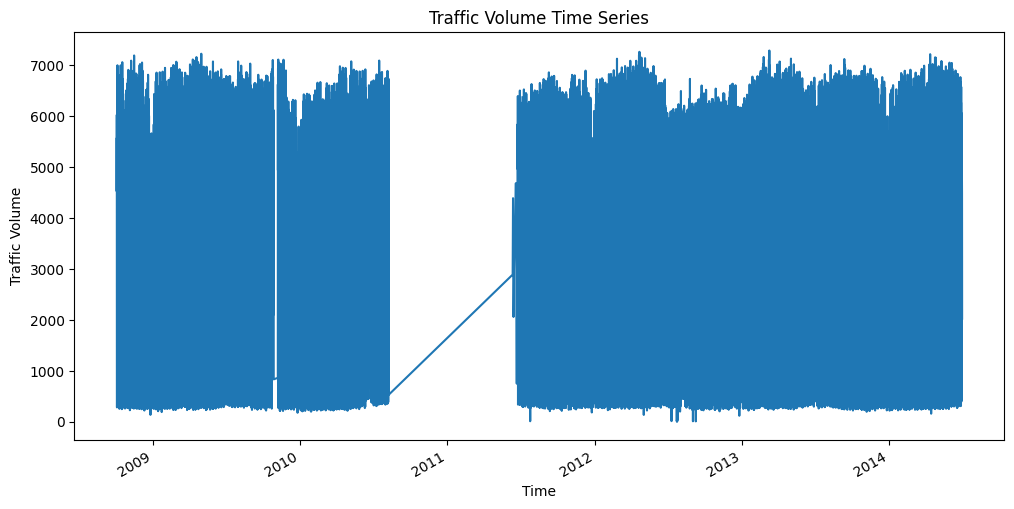

In [13]:
plt.figure(figsize=(12,6))
train_df['Traffic_Vol'].plot()
plt.title('Traffic Volume Time Series')
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.show()

In [14]:
train_df.isna().sum()

Holiday               38323
Temperature               0
Rainfall_last_hour        0
Snowfall_last_hour        0
Cloud_Cover               0
Weather                   0
Weather_Desc              0
Date                      0
Traffic_Vol               0
Hour                      0
Day                       0
Month                     0
Year                      0
Weekday                   0
dtype: int64

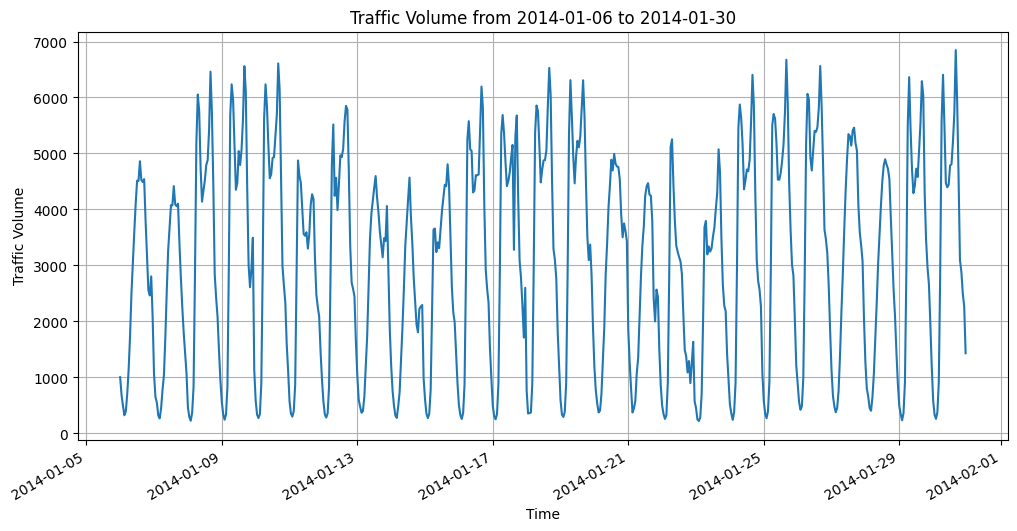

In [15]:
start_date = '2014-01-06'  
end_date = '2014-01-30'  

df_week = train_df.loc[start_date:end_date]


plt.figure(figsize=(12,6))
df_week['Traffic_Vol'].plot()
plt.title('Traffic Volume from {} to {}'.format(start_date, end_date))
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.grid(True)
plt.show()

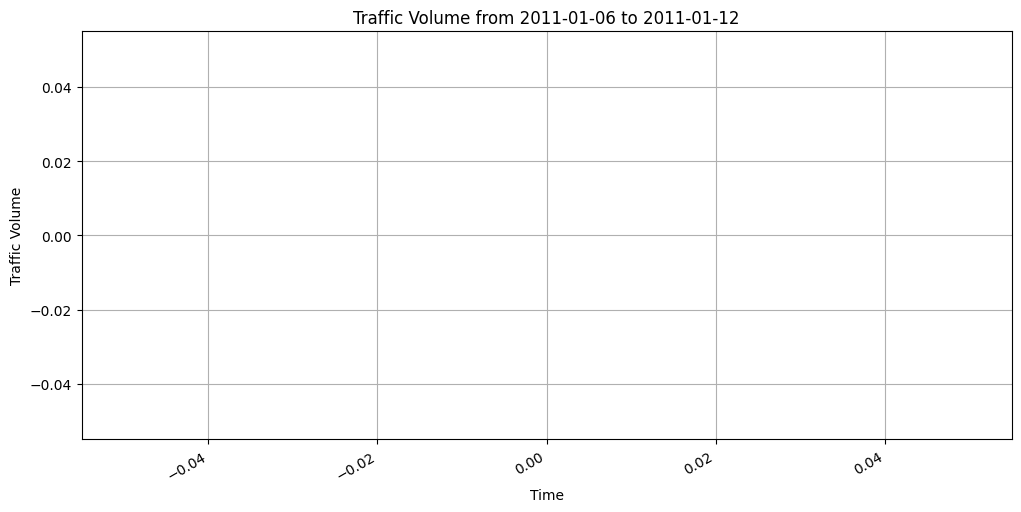

In [16]:
start_date = '2011-01-06'  
end_date = '2011-01-12'  

df_week = train_df.loc[start_date:end_date]


plt.figure(figsize=(12,6))
df_week['Traffic_Vol'].plot()
plt.title('Traffic Volume from {} to {}'.format(start_date, end_date))
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.grid(True)
plt.show()

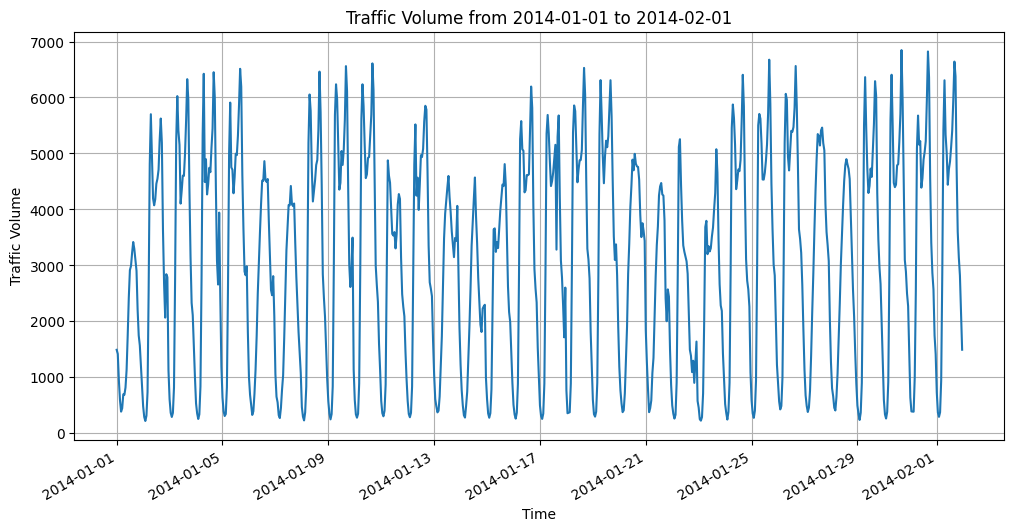

In [17]:
start_date = '2014-01-01'  
end_date = '2014-02-01'  

df_month = train_df.loc[start_date:end_date]


plt.figure(figsize=(12,6))
df_month['Traffic_Vol'].plot()
plt.title('Traffic Volume from {} to {}'.format(start_date, end_date))
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.grid(True)
plt.show()

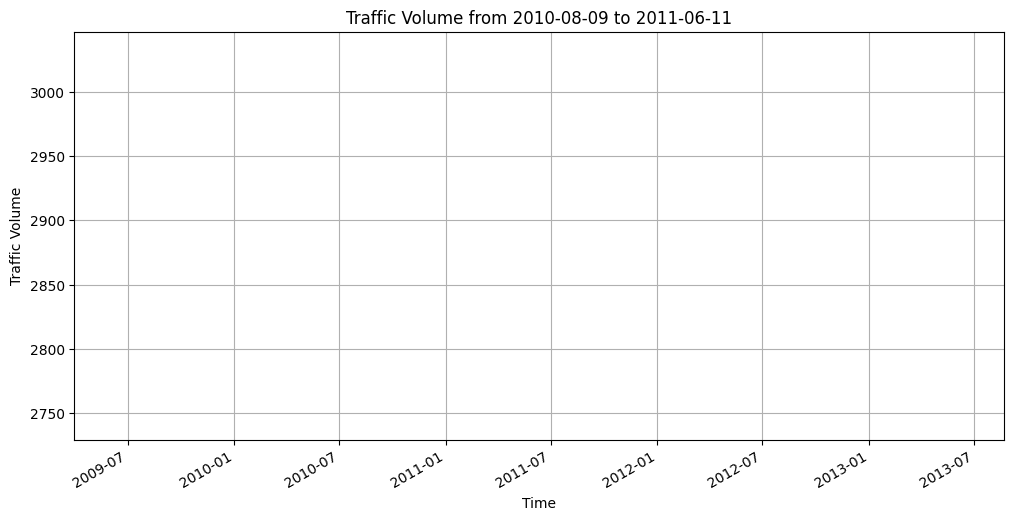

In [18]:
start_date = '2010-08-09'  
end_date = '2011-06-11'  

df_month = train_df.loc[start_date:end_date]


plt.figure(figsize=(12,6))
df_month['Traffic_Vol'].plot()
plt.title('Traffic Volume from {} to {}'.format(start_date, end_date))
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.grid(True)
plt.show()

In [19]:
train_df.head()

,Holiday,Temperature,Rainfall_last_hour,Snowfall_last_hour,Cloud_Cover,Weather,Weather_Desc,Date,Traffic_Vol,Hour,Day,Month,Year,Weekday
TimeStamp,,,,,,,,,,,,,,
2008-10-02 09:00:00,NaN,289.28,0.0,0.0,40,Cloudy skies,Partly cloudy skies,02/10/08,5555,9,2,10,2008,3
2008-10-02 10:00:00,NaN,290.26,0.0,0.0,75,Cloudy skies,Fragmented clouds,02/10/08,4525,10,2,10,2008,3
2008-10-02 11:00:00,NaN,290.28,0.0,0.0,90,Cloudy skies,Full cloud cover,02/10/08,4772,11,2,10,2008,3
2008-10-02 12:00:00,NaN,290.33,0.0,0.0,90,Cloudy skies,Full cloud cover,02/10/08,5031,12,2,10,2008,3
2008-10-02 13:00:00,NaN,292.14,0.0,0.0,75,Cloudy skies,Fragmented clouds,02/10/08,4928,13,2,10,2008,3


In [20]:
train_df.shape

(38373, 14)

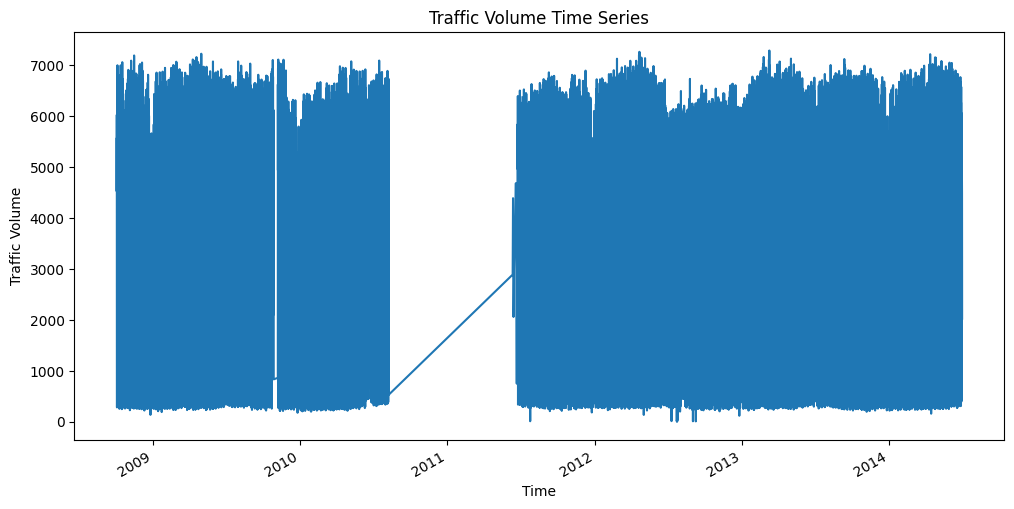

In [21]:
plt.figure(figsize=(12,6))
train_df['Traffic_Vol'].plot()
plt.title('Traffic Volume Time Series')
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.show()

<Figure size 1200x600 with 0 Axes>

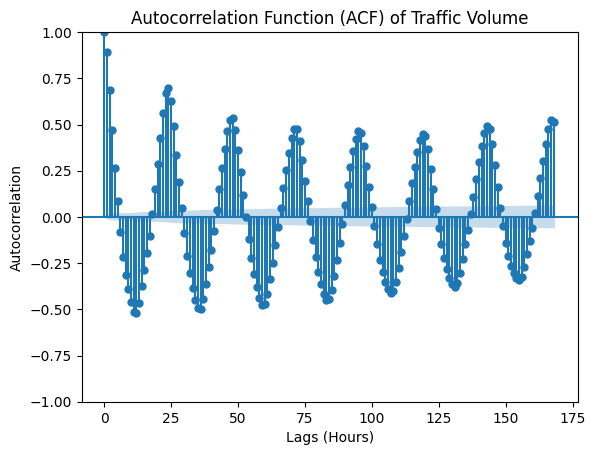

In [22]:
plt.figure(figsize=(12,6))
plot_acf(train_df['Traffic_Vol'], lags=168) 
plt.title('Autocorrelation Function (ACF) of Traffic Volume')
plt.xlabel('Lags (Hours)')
plt.ylabel('Autocorrelation')
plt.show()

In [23]:
train_df.sort_values('TimeStamp', inplace=True)
train_df.reset_index(drop=True, inplace=True)

In [24]:
train_df['IsWeekend'] = train_df['Weekday'].apply(lambda x: 1 if x >=5 else 0)

In [25]:
train_df['IsHoliday'] = train_df['Holiday'].notnull().astype(int)

In [26]:
label_encoder_weather = LabelEncoder()
train_df['Weather_encoded'] = label_encoder_weather.fit_transform(train_df['Weather'])

In [27]:
label_encoder_weather_desc = LabelEncoder()
train_df['Weather_Desc_encoded'] = label_encoder_weather_desc.fit_transform(train_df['Weather_Desc'])

In [28]:
train_df.drop(['Date', 'Holiday', 'Weather', 'Weather_Desc'], axis=1, inplace=True)

In [29]:
train_df.fillna(method='ffill', inplace=True)

In [30]:
train_df.head()

,Temperature,Rainfall_last_hour,Snowfall_last_hour,Cloud_Cover,Traffic_Vol,Hour,Day,Month,Year,Weekday,IsWeekend,IsHoliday,Weather_encoded,Weather_Desc_encoded
0,289.28,0.0,0.0,40,5555,9,2,10,2008,3,0,0,3,19
1,290.26,0.0,0.0,75,4525,10,2,10,2008,3,0,0,3,9
2,290.28,0.0,0.0,90,4772,11,2,10,2008,3,0,0,3,10
3,290.33,0.0,0.0,90,5031,12,2,10,2008,3,0,0,3,10
4,292.14,0.0,0.0,75,4928,13,2,10,2008,3,0,0,3,9


In [31]:
train_df.shape

(38373, 14)

In [32]:
train_df['Hour_sin'] = np.sin(2 * np.pi * train_df['Hour'] / 24)
train_df['Hour_cos'] = np.cos(2 * np.pi * train_df['Hour'] / 24)

train_df['Day_sin'] = np.sin(2 * np.pi * train_df['Day'] / 31)
train_df['Day_cos'] = np.cos(2 * np.pi * train_df['Day'] / 31)

train_df['Month_sin'] = np.sin(2 * np.pi * train_df['Month'] / 12)
train_df['Month_cos'] = np.cos(2 * np.pi * train_df['Month'] / 12)

In [33]:
train_df['IsMorning'] = (train_df['Hour'] >= 6) & (train_df['Hour'] < 12)
train_df['IsAfternoon'] = (train_df['Hour'] >= 12) & (train_df['Hour'] < 18)
train_df['IsEvening'] = (train_df['Hour'] >= 18) & (train_df['Hour'] < 24)

In [34]:
train_df.shape

(38373, 23)

In [35]:
train_df['Traffic_Vol'] = train_df['Traffic_Vol']**1.1405

In [36]:
features = train_df.drop(['Traffic_Vol'], axis=1)
target = train_df['Traffic_Vol']

In [37]:
scaler_features = MinMaxScaler()
scaled_features = scaler_features.fit_transform(features)

scaler_target = MinMaxScaler()
scaled_target = scaler_target.fit_transform(target.values.reshape(-1,1))

In [38]:
n_past = 168 
n_future = 1

In [39]:
X = []
y = []

for i in range(n_past, len(scaled_features) - n_future +1):
    X.append(scaled_features[i - n_past:i, :])
    y.append(scaled_target[i + n_future -1:i + n_future, 0])

X, y = np.array(X), np.array(y)

In [40]:
train_size = int(X.shape[0] * 0.9)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

In [41]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_past, X.shape[2])),
    tf.keras.layers.LSTM(128, return_sequences=True),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.LSTM(32, return_sequences=True),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(1)
])

model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 168, 128)          77312     
                                                                 
 lstm_1 (LSTM)               (None, 168, 64)           49408     
                                                                 
 lstm_2 (LSTM)               (None, 168, 32)           12416     
                                                                 
 lstm_3 (LSTM)               (None, 16)                3136      
                                                                 
 dense (Dense)               (None, 1)                 17        
                                                                 
Total params: 142289 (555.82 KB)
Trainable params: 142289 (555.82 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [42]:
model.compile(optimizer='adam', loss='mean_squared_error')

In [43]:
history = model.fit(X_train, y_train, epochs=10, batch_size=64, validation_data=(X_test, y_test), verbose=1)

Epoch 1/10

538/538 [==============================] - 205s 366ms/step - loss: 0.0218 - val_loss: 0.0086
Epoch 2/10
538/538 [==============================] - 115s 214ms/step - loss: 0.0100 - val_loss: 0.0048
Epoch 3/10
538/538 [==============================] - 117s 217ms/step - loss: 0.0085 - val_loss: 0.0046
Epoch 4/10
538/538 [==============================] - 115s 213ms/step - loss: 0.0077 - val_loss: 0.0051
Epoch 5/10
538/538 [==============================] - 116s 216ms/step - loss: 0.0070 - val_loss: 0.0045
Epoch 6/10
538/538 [==============================] - 118s 219ms/step - loss: 0.0063 - val_loss: 0.0050
Epoch 7/10
538/538 [==============================] - 118s 220ms/step - loss: 0.0060 - val_loss: 0.0054
Epoch 8/10
538/538 [==============================] - 125s 233ms/step - loss: 0.0055 - val_loss: 0.0043
Epoch 9/10
538/538 [==============================] - 128s 238ms/step - loss: 0.0051 - val_loss: 0.0054
Epoch 10/10
538/538 [==============================] - 124s 231

In [44]:
y_pred = model.predict(X_test)

120/120 [==============================] - 7s 43ms/step


In [45]:
y_pred_inv = scaler_target.inverse_transform(y_pred)
y_test_inv = scaler_target.inverse_transform(y_test.reshape(-1,1))

In [46]:
mse = mean_squared_error(y_test_inv, y_pred_inv)
mae = mean_absolute_error(y_test_inv, y_pred_inv)
r2 = r2_score(y_test_inv, y_pred_inv)

print('Mean Squared Error:', mse)
print('Mean Absolute Error:', mae)
print('R-squared:', r2)

Mean Squared Error: 3115960.0790027645
Mean Absolute Error: 1093.0205358353026
R-squared: 0.9370402100172126


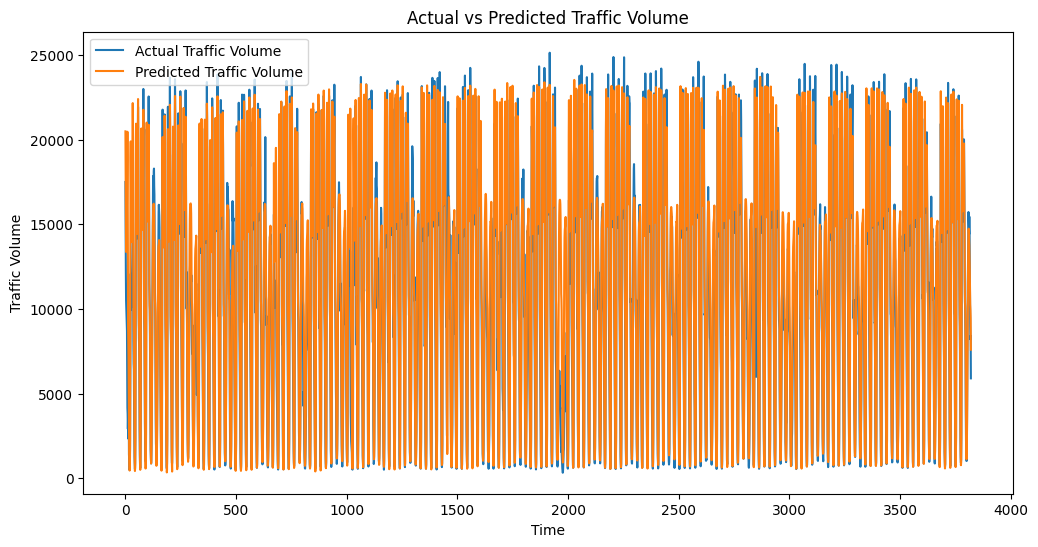

In [47]:
plt.figure(figsize=(12,6))
plt.plot(y_test_inv, label='Actual Traffic Volume')
plt.plot(y_pred_inv, label='Predicted Traffic Volume')
plt.title('Actual vs Predicted Traffic Volume')
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.legend()
plt.show()

In [48]:
model.fit(X, y)

1194/1194 [==============================] - 182s 152ms/step - loss: 0.0052


In [49]:
test_df['TimeStamp'] = pd.to_datetime(test_df['TimeStamp'], format='%d/%m/%y %H:%M')
test_df.sort_values('TimeStamp', inplace=True)
test_df.reset_index(drop=True, inplace=True)
test_df['Hour'] = test_df['TimeStamp'].dt.hour
test_df['Day'] = test_df['TimeStamp'].dt.day
test_df['Month'] = test_df['TimeStamp'].dt.month
test_df['Year'] = test_df['TimeStamp'].dt.year
test_df['Weekday'] = test_df['TimeStamp'].dt.weekday
test_df['IsWeekend'] = test_df['Weekday'].apply(lambda x: 1 if x >=5 else 0)
test_df['IsHoliday'] = test_df['Holiday'].notnull().astype(int)
test_df.fillna(method='ffill', inplace=True)
test_df['Weather_encoded'] = label_encoder_weather.transform(test_df['Weather'])
test_df['Weather_Desc_encoded'] = label_encoder_weather_desc.transform(test_df['Weather_Desc'])
test_df.drop(['Holiday', 'Weather', 'Weather_Desc', 'Traffic_Vol'], axis=1, inplace=True)
test_df['Hour_sin'] = np.sin(2 * np.pi * test_df['Hour'] / 24)
test_df['Hour_cos'] = np.cos(2 * np.pi * test_df['Hour'] / 24)
test_df['Day_sin'] = np.sin(2 * np.pi * test_df['Day'] / 31)
test_df['Day_cos'] = np.cos(2 * np.pi * test_df['Day'] / 31)
test_df['Month_sin'] = np.sin(2 * np.pi * test_df['Month'] / 12)
test_df['Month_cos'] = np.cos(2 * np.pi * test_df['Month'] / 12)
test_df['IsMorning'] = (test_df['Hour'] >= 6) & (test_df['Hour'] < 12)
test_df['IsAfternoon'] = (test_df['Hour'] >= 12) & (test_df['Hour'] < 18)
test_df['IsEvening'] = (test_df['Hour'] >= 18) & (test_df['Hour'] < 24)

In [50]:
test_df.shape

(2208, 24)

In [51]:
set(train_df.columns) - set(test_df.columns)

{'Traffic_Vol'}

In [52]:
timestamps_test = test_df['TimeStamp']
test_df_features = test_df.drop(['TimeStamp', 'Date'], axis=1)

In [53]:
features.shape

(38373, 22)

In [54]:
test_df_features.shape

(2208, 22)

In [55]:
last_train_features = features.iloc[-n_past:]
combined_features = pd.concat([last_train_features, test_df_features], ignore_index=True)
scaled_combined_features = scaler_features.transform(combined_features)

In [56]:
X_test_full = []
sequence_length = n_past

for i in range(sequence_length, len(scaled_combined_features)):
    X_test_full.append(scaled_combined_features[i - sequence_length:i, :])

X_test_full = np.array(X_test_full)


In [57]:
test_timestamps = timestamps_test.values

In [58]:
y_pred_test_scaled = model.predict(X_test_full)
y_pred_test = scaler_target.inverse_transform(y_pred_test_scaled)

69/69 [==============================] - 3s 45ms/step


In [59]:
predictions_df = pd.DataFrame({
    'TimeStamp': test_timestamps,
    'Predicted_Traffic_Vol': y_pred_test.flatten()
})

In [60]:
predictions_df['Predicted_Traffic_Vol'] = predictions_df['Predicted_Traffic_Vol'] ** (1/1.138)

In [61]:
sub_df.shape

(2208, 1)

In [62]:
sub_df['Traffic_Vol'] = predictions_df['Predicted_Traffic_Vol']

In [63]:
sub_df.head()

,Traffic_Vol
0,1660.311279
1,1030.652344
2,647.661255
3,490.771240
4,519.801392


In [64]:
import joblib
import os

# Create models directory
os.makedirs("saved_models", exist_ok=True)

# Save trained LSTM model
model.save("saved_models/traffic_lstm_model.keras")

# Save feature scaler
joblib.dump(
    scaler_features,
    "saved_models/feature_scaler.pkl"
)

# Save target scaler
joblib.dump(
    scaler_target,
    "saved_models/target_scaler.pkl"
)

# Save label encoders
joblib.dump(
    label_encoder_weather,
    "saved_models/weather_encoder.pkl"
)

joblib.dump(
    label_encoder_weather_desc,
    "saved_models/weather_desc_encoder.pkl"
)

# Save feature column order
feature_columns = features.columns.tolist()

joblib.dump(
    feature_columns,
    "saved_models/feature_columns.pkl"
)

# Save sequence information
joblib.dump(
    n_past,
    "saved_models/n_past.pkl"
)

print("\nModel and preprocessing objects saved successfully!")
print("Model path: saved_models/traffic_lstm_model.keras")


Model and preprocessing objects saved successfully!
Model path: saved_models/traffic_lstm_model.keras
